# Thin-sheet FDEM forward modeling in Python: horizontal sheet

In [1]:
import os
import re
import time
import warnings
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from scipy.linalg import lu_factor, lu_solve

# physical constants, as in the Fortran main program
PI = 4.0 * np.arctan(1.0)
EPS0 = 8.85419e-12
AMYU0 = 4.0e-7 * PI
CONV = PI / 180.0
PI4 = 0.25 / PI

# numerical settings of the Fortran sources
NP_CELL = 9
NP_SING = 15
EPS_ROMB = 1.0e-6
K_ROMB = 5
JMAX_ROMB = 20
MAX_PTS = 2_000_000

plt.rcParams.update({
    "font.size": 11, "axes.titlesize": 11, "axes.labelsize": 11, "legend.fontsize": 10.5,
    "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True, "ytick.right": True,
    "xtick.minor.visible": True, "ytick.minor.visible": True,
    "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.5,
    "legend.frameon": False, "lines.linewidth": 1.8, "savefig.dpi": 300, "savefig.bbox": "tight",
})
STYLE = {"X": dict(color="black", ls="-"),
         "Y": dict(color="#1f5fbf", ls="--"),
         "Z": dict(color="#c62828", ls="-.")}

## Settings

`FREQUENCIES`, `SHEET_CONDUCTIVITY`, `SHEET_DIP` and `SHEET_Z` define the test. The rest of the model and the survey are in `PAR_TEXT`, which has the format of the WSHEET parameter file. With a dip of zero the whole sheet lies at z = `SHEET_Z`, with its strike length along y and its other side along x.

In [2]:
FREQUENCIES = [20000.0, 10.0]                      # Hz
SHEET_CONDUCTIVITY = 1.0e5                         # S/m (the sheet thickness is in PAR_TEXT, 0.1 m)
SHEET_DIP = 0.0                                    # degrees, 0 = horizontal
SHEET_Z = -100.0                                   # m, z of the horizontal sheet (z_top in the parameter file)
STATIONS = [400.0, 450.0, 500.0, 550.0, 600.0]     # receiver positions (m) for the curves against frequency
EXACT_SELF_CELL = True                             # False: self cell as in the Fortran code, True: exact rectangle (not in the Fortran)

PAR_TEXT = """>> No. of sheet
1
>> No. of cells for strike and dip direction (max = 20)
20  20
>> xyz coordinate of the center of the sheets before rotation 
500.  0. -200.
>> strike length (m), dip length(m), strike (deg), dip (deg),thickness(m) of each sheet
200. 200.  90. 90. 0.1
>> Cole-Cole parameter of resistivity of each sheet
1.d-5  1.d-6  0.  0.5
>> Cole-Cole parameter of relative permittivity of each sheet
2.   2.  0.  0.5
>> Cole-Cole parameter of resistivity of whole space
10. 10.  0.  0.5
>> Cole-Cole parameter of dielectric constant of whole space
10.  10.  0.  0.5
>> Frequency (Hz)
20.d3
>> source type (0=plane, 1=J type, 2=M type), direction (1=x,2=y,3=z), angle
2   3   0.
>> No. of Tx
1
>> start x,y,z coordinates of the sources and increments
0., 0., 0.0
0.,  0.,  0.0
>> No. of Rx
201
>> start x,y,z coordinates of the Receivers and increments
0., 0.,  0.75
5.,  0.,  0.0
>> Perform Green's function integral and SVD (0,1) or use previous SVD data(2)
2
>> output control parameter scattering, e_field, h_field, normalizing
1  1  0  0
"""


def par_for(freq):
    """PAR_TEXT with the sheet laid at SHEET_Z with dip SHEET_DIP, its resistivity set to 1/SHEET_CONDUCTIVITY,
    the frequency replaced and it_s set to 1."""
    lines = PAR_TEXT.split("\n")
    after = lambda start: next(i for i, l in enumerate(lines) if l.startswith(start)) + 1
    numbers = lambda line: [float(re.sub("[dD]", "e", t)) for t in line.replace(",", " ").split()]
    rho = 1.0 / float(SHEET_CONDUCTIVITY)
    lines[after(">> Cole-Cole parameter of resistivity of each sheet")] = "%r  %r  0.  0.5" % (rho, rho)
    lines[after(">> Frequency")] = "%r" % float(freq)
    lines[after(">> Perform")] = "1"
    i_xyz = after(">> xyz coordinate")
    x_top, y_top, _ = numbers(lines[i_xyz])
    lines[i_xyz] = "%r  %r  %r" % (x_top, y_top, float(SHEET_Z))
    i_geo = after(">> strike length")
    aa, bb, strike, _, thick = numbers(lines[i_geo])
    lines[i_geo] = "%r  %r  %r  %r  %r" % (aa, bb, strike, float(SHEET_DIP), thick)
    return "\n".join(lines)


def par_name(freq):
    return "wsheet20_horizontal_%gHz.par" % freq


for f in FREQUENCIES:
    with open(par_name(f), "w") as fh:
        fh.write(par_for(f))
print("sheet conductivity %g S/m, dip %g deg, z = %g m, frequencies %s Hz"
      % (SHEET_CONDUCTIVITY, SHEET_DIP, SHEET_Z, ", ".join("%g" % f for f in FREQUENCIES)))

sheet conductivity 100000 S/m, dip 0 deg, z = -100 m, frequencies 20000, 10 Hz


## Forward-modeling code

Parameter reader, material properties, numerical integration, sheet geometry, Green's tensor integrals and system matrix, source fields, sheet currents and secondary fields, and the main program.

In [3]:
_NUM = re.compile(r"^[+-]?(\d+\.?\d*|\.\d+)([eEdD][+-]?\d+)?$")


def _values(line, n):
    """Read n numbers from one record the way a Fortran list-directed READ does."""
    out = []
    for tok in line.replace(",", " ").split():
        if not _NUM.match(tok):
            break
        out.append(float(re.sub("[dD]", "e", tok)))
        if len(out) == n:
            break
    if len(out) < n:
        raise ValueError("could not read %d values from: %r" % (n, line))
    return out


def read_par(fname="wsheet20.par"):
    """Translation of the READ block of the main program (file wsheet20.par)."""
    with open(fname) as f:
        lines = f.read().replace("\r", "").split("\n")
    pos = [0]

    def skip():
        pos[0] += 1

    def rd(n):
        v = _values(lines[pos[0]], n)
        pos[0] += 1
        return v

    p = SimpleNamespace()
    p.na = np.zeros(2, dtype=int)
    p.nb = np.zeros(2, dtype=int)
    for name in ("aa", "bb", "alpha", "beta", "x_top", "y_top", "z_top", "thick",
                 "strike_deg", "dip_deg"):
        setattr(p, name, np.zeros(2))
    p.res = [None, None]
    p.eps = [None, None]

    skip()
    p.no_sheet = int(rd(1)[0])
    ns = p.no_sheet
    skip()
    for i in range(ns):
        v = rd(2)
        p.na[i], p.nb[i] = int(v[0]), int(v[1])
    skip()
    for i in range(ns):
        p.x_top[i], p.y_top[i], p.z_top[i] = rd(3)
    skip()
    for i in range(ns):
        aa, bb, alp, bet, th = rd(5)
        p.strike_deg[i], p.dip_deg[i] = alp, bet
        if bet != 0.0:
            bet = 180.0 - bet
        p.aa[i], p.bb[i], p.thick[i] = aa, bb, th
        p.alpha[i] = alp * CONV
        p.beta[i] = bet * CONV
    skip()
    for i in range(ns):
        p.res[i] = tuple(rd(4))
    skip()
    for i in range(ns):
        p.eps[i] = tuple(rd(4))
    skip()
    p.resn = tuple(rd(4))
    skip()
    p.epsn = tuple(rd(4))
    skip()
    p.freq = rd(1)[0]
    skip()
    v = rd(3)
    p.ns_type, p.ns_dir, p.angle_deg = int(v[0]), int(v[1]), v[2]
    skip()
    p.n_tx = int(rd(1)[0])
    skip()
    p.xs_s = np.array(rd(3))
    p.xs_i = np.array(rd(3))
    skip()
    p.n_rx = int(rd(1)[0])
    skip()
    p.xr_s = np.array(rd(3))
    p.xr_i = np.array(rd(3))
    skip()
    p.it_s = int(rd(1)[0])
    skip()
    p.nprt = [int(v) for v in rd(4)]
    return p

In [4]:
def cole(z_l, z_h, tau, alpha, omega):
    """Fortran: complex function cole(z_l,z_h,tau,alpha)."""
    i_om = 1j * omega
    if (z_l < z_h) or (alpha > 1.0):
        raise ValueError(">> INVALID COLE-COLE PARAMETERS !!")
    if tau < 1.0e-12:
        return complex(z_l, 0.0)
    return z_h + (z_l - z_h) / (1.0 + (i_om * tau) ** alpha)


def ddcos(arg):
    """Fortran: real function ddcos(arg). Cosine set to zero within 0.01 rad of 90 degrees."""
    if abs(PI / 2.0 - arg) < 1.0e-2:
        return 0.0
    return float(np.cos(arg))


def facto(nmax):
    """Fortran: real function facto(nmax)."""
    fact = 1.0
    for i in range(1, nmax + 1):
        fact *= float(i)
    return fact


def setup_model(p):
    """Translation of the part of the main program between the READ block and GREEN_0."""
    ns = p.no_sheet
    p.n_col = 2 * (p.na[0] * p.nb[0] + p.na[1] * p.nb[1])
    p.angle = p.angle_deg * CONV
    p.omega = 2.0 * PI * p.freq
    i_om = 1j * p.omega

    res_n = cole(*p.resn, p.omega)
    eps_n = cole(*p.epsn, p.omega) * EPS0
    sig_n = 0.0
    if abs(res_n) > 0.0:
        sig_n = 1.0 / res_n
    p.tau = np.zeros(2, dtype=complex)
    for i in range(ns):
        res = cole(*p.res[i], p.omega)
        eps = cole(*p.eps[i], p.omega) * EPS0
        sig = 1.0 / res
        sig = sig - sig_n
        eps = eps - eps_n
        p.tau[i] = (sig + i_om * eps) * p.thick[i]

    p.admit = sig_n + i_om * eps_n
    p.imped = i_om * AMYU0
    p.wave_s = -p.admit * p.imped
    p.ikk = 1j * np.sqrt(complex(p.wave_s))

    nab1 = p.na[0] * p.nb[0]
    p.off_unknown = [0, 2 * nab1]
    p.off_cell = [0, nab1]
    return p

In [5]:
def _polint0(xa, ya):
    """Fortran: POLINT(XA,YA,N,X,Y,DY) with X = 0. ya has shape (N, m)."""
    n = len(xa)
    c = ya.copy()
    d = ya.copy()
    ns1 = int(np.argmin(np.abs(np.asarray(xa)))) + 1
    y = ya[ns1 - 1].copy()
    ns1 -= 1
    dy = np.zeros_like(y)
    for m in range(1, n):
        for i in range(n - m):
            ho = xa[i]
            hp = xa[i + m]
            w = c[i + 1] - d[i]
            den = w / (ho - hp)
            d[i] = hp * den
            c[i] = ho * den
        if 2 * ns1 < n - m:
            dy = c[ns1].copy()
        else:
            dy = d[ns1 - 1].copy()
            ns1 -= 1
        y = y + dy
    return y, dy


def qromb(i_d, xx, yy, zz, a, b, ikk, eps=EPS_ROMB, jmax=JMAX_ROMB, k=K_ROMB):
    """Fortran: QROMB(FUNC,A,B,SS) with FUNC = DERIV, for arrays of integrals."""
    arrs = np.broadcast_arrays(*[np.asarray(v, dtype=float) for v in (xx, yy, zz, a, b)])
    shape = arrs[0].shape
    xx, yy, zz, a, b = [v.ravel() for v in arrs]
    n = xx.size
    c2 = xx * xx + zz * zz
    ba = b - a

    def func(idx, x):
        if x.ndim == 2:
            rr = np.sqrt(c2[idx, None] + (yy[idx, None] - x) ** 2)
        else:
            rr = np.sqrt(c2[idx] + (yy[idx] - x) ** 2)
        ikr = ikk * rr
        pot = np.exp(-ikr) / rr
        if i_d == 0:
            return pot
        return pot * (1.0 + ikr) / rr ** 2

    ssr = np.zeros(n)
    ssi = np.zeros(n)
    act = np.arange(n)
    conv_r = np.zeros(n, dtype=bool)
    conv_i = np.zeros(n, dtype=bool)
    hist, hs = [], []
    h = 1.0
    s = None
    for j in range(1, jmax + 1):
        if j == 1:
            s = 0.5 * ba * (func(act, a) + func(act, b))
        else:
            it = 2 ** (j - 2)
            t = (np.arange(it) + 0.5) / it
            summ = np.empty(act.size, dtype=complex)
            blk = max(1, MAX_PTS // it)
            for s0 in range(0, act.size, blk):
                idx = act[s0:s0 + blk]
                x = a[idx, None] + ba[idx, None] * t[None, :]
                summ[s0:s0 + blk] = func(idx, x).sum(axis=1)
            s = 0.5 * (s + ba[act] * summ / it)
        hist.append(s)
        hs.append(h)
        if len(hist) > k:
            hist.pop(0)
            hs.pop(0)
        if j >= k:
            ya = np.array(hist)
            y_r, dy_r = _polint0(hs, ya.real)
            y_i, dy_i = _polint0(hs, ya.imag)
            upd = ~conv_r[act]
            ssr[act[upd]] = y_r[upd]
            conv_r[act[upd]] = np.abs(dy_r[upd]) < eps * np.abs(y_r[upd])
            upd = ~conv_i[act]
            ssi[act[upd]] = y_i[upd]
            conv_i[act[upd]] = np.abs(dy_i[upd]) < eps * np.abs(y_i[upd])
            done = conv_r[act] & conv_i[act]
            if done.all():
                act = act[:0]
                break
            if done.any():
                keep = ~done
                act = act[keep]
                s = s[keep]
                hist = [hh[keep] for hh in hist]
        h *= 0.25
    if act.size > 0:
        warnings.warn("qromb: %d of %d integrals not converged after %d levels "
                      "(last estimate returned)" % (act.size, n, jmax))
    return (ssr + 1j * ssi).reshape(shape)


def spline_weights(n):
    """Weights w such that sum(w*f) is the integral over [0,1] of the not-a-knot cubic"""
    x = np.linspace(0.0, 1.0, n)
    w = np.empty(n)
    for i in range(n):
        e = np.zeros(n)
        e[i] = 1.0
        w[i] = CubicSpline(x, e, bc_type="not-a-knot").integrate(0.0, 1.0)
    return w


W_CELL = spline_weights(NP_CELL)
W_SING = spline_weights(NP_SING)
U_CELL = np.arange(NP_CELL) / (NP_CELL - 1.0)


def _sum_da(x):
    """sum over m,n of da(m,n) * x(k+m, l+n) for all nodes (k,l); x is padded by one cell."""
    return x[..., :-1, :-1] + x[..., :-1, 1:] - x[..., 1:, :-1] - x[..., 1:, 1:]


def _sum_db(x):
    """sum over m,n of db(m,n) * x(k+m, l+n) for all nodes (k,l); x is padded by one cell."""
    return x[..., :-1, :-1] - x[..., :-1, 1:] + x[..., 1:, :-1] - x[..., 1:, 1:]


def _pad(x):
    """Embed cell values (1..na, 1..nb) in the zero-bordered array (0..na+1, 0..nb+1)."""
    out = np.zeros(x.shape[:-2] + (x.shape[-2] + 2, x.shape[-1] + 2), dtype=complex)
    out[..., 1:-1, 1:-1] = x
    return out

In [6]:
def ts_grid(p):
    """Fortran: subroutine ts_grid. x,y,z coordinates of the cell centres of all sheets."""
    ncell = p.na[0] * p.nb[0] + p.na[1] * p.nb[1]
    x_loc = np.zeros(ncell)
    y_loc = np.zeros(ncell)
    z_loc = np.zeros(ncell)
    for is_ in range(p.no_sheet):
        naa, nbb = p.na[is_], p.nb[is_]
        iskip = p.off_cell[is_]
        del_a = p.aa[is_] / naa
        del_b = p.bb[is_] / nbb
        da_cos = ddcos(p.alpha[is_])
        da_sin = np.sin(p.alpha[is_])
        db_cos = ddcos(p.beta[is_])
        db_sin = np.sin(p.beta[is_])
        a_init = -0.5 * p.aa[is_]
        b_init = -0.5 * p.bb[is_]
        z_rise = b_init * db_sin
        a_temp = (a_init + (np.arange(1, naa + 1) - 0.5) * del_a)[:, None]
        b_temp = (b_init + (np.arange(1, nbb + 1) - 0.5) * del_b)[None, :]
        sl = slice(iskip, iskip + naa * nbb)
        x_loc[sl] = (p.x_top[is_] + a_temp * da_cos - b_temp * da_sin * db_cos).ravel()
        y_loc[sl] = (p.y_top[is_] + a_temp * da_sin + b_temp * da_cos * db_cos).ravel()
        z_loc[sl] = (p.z_top[is_] + b_temp * db_sin - z_rise + 0.0 * a_temp).ravel()
    return x_loc, y_loc, z_loc

In [7]:
def singular(p, del_a, del_b):
    """Fortran: subroutine singular (del_a, del_b, saa, faa, fbb)."""
    ikk = p.ikk
    de = min(del_a, del_b)
    del2 = de / 2.0
    dif = abs(del_a - del_b) / 2.0
    if dif < 1.0e-6 * de:
        dif = 0.0
    f_l = del2 + dif

    rho = de / np.sqrt(PI)
    ikrho = ikk * rho
    e_ikrho = np.exp(-ikrho)
    faa = -0.25 * (1.0 + ikrho) * e_ikrho / rho
    fbb = faa

    if abs(ikk) > 1.0e-3:
        saa = 0.5 * (1.0 - e_ikrho) / ikk
    elif abs(ikk) == 0.0:
        saa = 0.5 * rho + 0.0j
    else:
        saa = 1.0 + 0.0j
        for i in range(2, 11):
            saa = saa + (-ikrho) ** (i - 1.0) / facto(i)
        saa = 0.5 * rho * saa

    if dif != 0.0:
        dfaa_f = qromb(1, del2, 0.0, 0.0, 0.0, del2, ikk)
        dfaa_i = qromb(1, f_l, 0.0, 0.0, 0.0, del2, ikk)
        faa = faa + (del2 * dfaa_f - f_l * dfaa_i) / PI
        dfbb = qromb(1, del2, 0.0, 0.0, del2, f_l, ikk)
        fbb = fbb - del2 * dfbb / PI
        d_i = np.arange(NP_SING) * del2 / (NP_SING - 1.0)
        d_j = del2 + np.arange(NP_SING) * dif / (NP_SING - 1.0)
        r_ij = np.sqrt(d_i[:, None] ** 2 + d_j[None, :] ** 2)
        pot = np.exp(-ikk * r_ij) / r_ij
        quad = (W_SING @ pot @ W_SING) * del2 * dif
        saa = saa + quad / PI
        if del_b > del_a:
            faa, fbb = fbb, faa

    if EXACT_SELF_CELL:
        la = qromb(1, np.array([0.5 * del_a, -0.5 * del_a]), 0.0, 0.0, -0.5 * del_b, 0.5 * del_b, ikk)
        lb = qromb(1, np.array([0.5 * del_b, -0.5 * del_b]), 0.0, 0.0, -0.5 * del_a, 0.5 * del_a, ikk)
        faa = -0.5 * del_a * (la[0] + la[1]) * PI4
        fbb = -0.5 * del_b * (lb[0] + lb[1]) * PI4
    return complex(saa), complex(faa), complex(fbb)


def green_0(p, is_, sysm):
    """Fortran: subroutine green_0 (is,ns,n_col,sys). is_ is the 0-based sheet index."""
    ikk, imped, wave_s = p.ikk, p.imped, p.wave_s
    ns = p.no_sheet
    ins = 1 - is_
    nap, nbp = p.na[is_], p.nb[is_]
    del_a = p.aa[is_] / nap
    del_b = p.bb[is_] / nbp
    nabp = nap * nbp
    nabp_1 = (nap - 1) * (nbp - 1)
    a_init = -0.5 * p.aa[is_]
    b_init = -0.5 * p.bb[is_]
    off = p.off_unknown[is_]
    ctau = p.tau[is_]

    def gexp(r):
        return np.exp(-ikk * r) / r

    ssaa, sfaa, sfbb = singular(p, del_a, del_b)

    a_c = a_init + (np.arange(1, nap + 1) - 0.5) * del_a
    b_c = b_init + (np.arange(1, nbp + 1) - 0.5) * del_b
    a_e = a_init + np.arange(nap + 1) * del_a
    b_e = b_init + np.arange(nbp + 1) * del_b
    nq = (nap + 1) * (nbp + 1) - 2
    jj = np.arange(nbp)

    for i in range(nap):
        a_i = a_c[i]
        a_di = a_i - a_e[:-1]
        a_df = a_i - a_e[1:]
        b_di = b_c[:, None] - b_e[None, :-1]
        b_df = b_c[:, None] - b_e[None, 1:]

        def e_c(av, bv):
            return gexp(np.sqrt(av[None, :, None] ** 2 + bv[:, None, :] ** 2))

        dfab = e_c(a_df, b_df) - e_c(a_df, b_di) - e_c(a_di, b_df) + e_c(a_di, b_di)

        la = qromb(1, (a_i - a_e)[None, :, None], b_c[:, None, None], 0.0,
                   b_e[None, None, :-1], b_e[None, None, 1:], ikk)
        lb = qromb(1, (b_c[:, None] - b_e[None, :])[:, None, :], a_i, 0.0,
                   a_e[None, :-1, None], a_e[None, 1:, None], ikk)
        dfaa = a_df[None, :, None] * la[:, 1:, :] - a_di[None, :, None] * la[:, :-1, :]
        dfbb = b_df[:, None, :] * lb[:, :, 1:] - b_di[:, None, :] * lb[:, :, :-1]

        xd = a_i - (a_e[:-1, None] + U_CELL[None, :] * del_a)
        yd = b_c[:, None, None] - (b_e[None, :-1, None] + U_CELL[None, None, :] * del_b)
        r_ij = np.sqrt(xd[None, :, None, :, None] ** 2 + yd[:, None, :, None, :] ** 2)
        r_ij[r_ij == 0.0] = 1.0
        dsaa = np.einsum("jklmn,m,n->jkl", gexp(r_ij), W_CELL, W_CELL) * del_a * del_b

        saa = PI4 * dsaa
        faa = PI4 * dfaa
        fbb = PI4 * dfbb
        fab = PI4 * dfab
        saa[jj, i, jj] = ssaa
        faa[jj, i, jj] = sfaa
        fbb[jj, i, jj] = sfbb
        fab[jj, i, jj] = 0.0

        a_arr = imped * _pad(saa)
        a_arr[jj, i + 1, jj + 1] += 1.0 / ctau
        faa_p, fbb_p, fab_p = _pad(faa), _pad(fbb), _pad(fab)
        paa = _sum_db(a_arr)
        pbb = _sum_da(a_arr)
        qaa = _sum_da(wave_s * a_arr + imped * faa_p)
        qab = _sum_db(imped * fab_p)
        qba = _sum_da(imped * fab_p)
        qbb = _sum_db(wave_s * a_arr + imped * fbb_p)

        rows_a = off + i * nbp + jj
        rows_b = rows_a + nabp
        if nabp_1 > 0:
            sl_p = slice(off, off + nabp_1)
            sysm[rows_a, sl_p] = (0.5 * paa[:, 1:nap, 1:nbp] / del_b).reshape(nbp, -1)
            sysm[rows_b, sl_p] = (-0.5 * pbb[:, 1:nap, 1:nbp] / del_a).reshape(nbp, -1)
        sl_q = slice(off + nabp_1, off + nabp_1 + nq)
        sysm[rows_a, sl_q] = (0.5 * (qaa / del_a + qab / del_b)).reshape(nbp, -1)[:, :nq]
        sysm[rows_b, sl_q] = (0.5 * (qba / del_a + qbb / del_b)).reshape(nbp, -1)[:, :nq]

    if ns == 1:
        return

    nas, nbs = p.na[ins], p.nb[ins]
    nabs_1 = (nas - 1) * (nbs - 1)
    del_as = p.aa[ins] / nas
    del_bs = p.bb[ins] / nbs
    as_init = -0.5 * p.aa[ins]
    bs_init = -0.5 * p.bb[ins]
    alp = p.alpha[is_] - p.alpha[ins]
    bet = p.beta[is_] - p.beta[ins]
    a_cos, a_sin = ddcos(alp), np.sin(alp)
    b_cos, b_sin = ddcos(bet), np.sin(bet)
    a_cos1, a_sin1 = ddcos(p.alpha[ins]), np.sin(p.alpha[ins])
    b_cos1, b_sin1 = ddcos(p.beta[ins]), np.sin(p.beta[ins])
    x_p1 = p.x_top[is_] - p.x_top[ins]
    y_p1 = p.y_top[is_] - p.y_top[ins]
    z_p1 = p.z_top[is_] - p.z_top[ins]
    x_p = x_p1 * a_cos1 + y_p1 * a_sin1
    y_p = -x_p1 * a_sin1 * b_cos1 + y_p1 * a_cos1 * b_cos1 + z_p1 * b_sin1
    z_p = x_p1 * a_sin1 * b_sin1 - y_p1 * a_cos1 * b_sin1 + z_p1 * b_cos1

    as_e = as_init + np.arange(nas + 1) * del_as
    bs_e = bs_init + np.arange(nbs + 1) * del_bs
    off_s = p.off_unknown[ins]
    nqs = (nas + 1) * (nbs + 1) - 2

    for i in range(nap):
        a_temp = a_c[i]
        b_temp = b_c
        xs = x_p + a_temp * a_cos - b_temp * a_sin * b_cos
        ys = y_p + a_temp * a_sin + b_temp * a_cos * b_cos
        zs = z_p + b_temp * b_sin
        as_i = xs[:, None] - as_e[None, :-1]
        as_f = xs[:, None] - as_e[None, 1:]
        bs_i = ys[:, None] - bs_e[None, :-1]
        bs_f = ys[:, None] - bs_e[None, 1:]
        zs2 = (zs ** 2)[:, None, None]

        def e_c(av, bv):
            return gexp(np.sqrt(av[:, :, None] ** 2 + bv[:, None, :] ** 2 + zs2))

        dfya = e_c(as_f, bs_f) - e_c(as_f, bs_i) - e_c(as_i, bs_f) + e_c(as_i, bs_i)

        la = qromb(1, (xs[:, None] - as_e[None, :])[:, :, None], ys[:, None, None],
                   zs[:, None, None], bs_e[None, None, :-1], bs_e[None, None, 1:], ikk)
        lb = qromb(1, (ys[:, None] - bs_e[None, :])[:, None, :], xs[:, None, None],
                   zs[:, None, None], as_e[None, :-1, None], as_e[None, 1:, None], ikk)
        dfxa = as_f[:, :, None] * la[:, 1:, :] - as_i[:, :, None] * la[:, :-1, :]
        dfza = zs[:, None, None] * (la[:, 1:, :] - la[:, :-1, :])
        dfyb = bs_f[:, None, :] * lb[:, :, 1:] - bs_i[:, None, :] * lb[:, :, :-1]
        dfzb = zs[:, None, None] * (lb[:, :, 1:] - lb[:, :, :-1])

        xd = xs[:, None, None] - (as_e[None, :-1, None] + U_CELL[None, None, :] * del_as)
        yd = ys[:, None, None] - (bs_e[None, :-1, None] + U_CELL[None, None, :] * del_bs)
        r_ij = np.sqrt(xd[:, :, None, :, None] ** 2 + yd[:, None, :, None, :] ** 2
                       + zs2[:, :, :, None, None])
        dsxa = np.einsum("jklmn,m,n->jkl", gexp(r_ij), W_CELL, W_CELL) * del_as * del_bs

        saa = _pad(PI4 * a_cos * dsxa)
        sab = _pad(PI4 * a_sin * dsxa)
        sba = _pad(-PI4 * a_sin * b_cos * dsxa)
        sbb = _pad(PI4 * a_cos * b_cos * dsxa)
        faa = _pad(PI4 * (a_cos * dfxa + a_sin * dfya))
        fab = _pad(PI4 * (a_cos * dfya + a_sin * dfyb))
        fba = _pad(PI4 * (-a_sin * b_cos * dfxa + a_cos * b_cos * dfya + b_sin * dfza))
        fbb = _pad(PI4 * (-a_sin * b_cos * dfya + a_cos * b_cos * dfyb + b_sin * dfzb))

        paa = _sum_db(imped * saa)
        pab = _sum_da(imped * sab)
        pba = _sum_db(imped * sba)
        pbb = _sum_da(imped * sbb)
        qaa = _sum_da(imped * (wave_s * saa + faa))
        qab = _sum_db(imped * (wave_s * sab + fab))
        qba = _sum_da(imped * (wave_s * sba + fba))
        qbb = _sum_db(imped * (wave_s * sbb + fbb))

        rows_a = off + i * nbp + jj
        rows_b = rows_a + nabp
        if nabs_1 > 0:
            sl_p = slice(off_s, off_s + nabs_1)
            sysm[rows_a, sl_p] = (0.5 * (paa / del_bs - pab / del_as))[:, 1:nas, 1:nbs].reshape(nbp, -1)
            sysm[rows_b, sl_p] = (0.5 * (pba / del_bs - pbb / del_as))[:, 1:nas, 1:nbs].reshape(nbp, -1)
        sl_q = slice(off_s + nabs_1, off_s + nabs_1 + nqs)
        sysm[rows_a, sl_q] = (0.5 * (qaa / del_as + qab / del_bs)).reshape(nbp, -1)[:, :nqs]
        sysm[rows_b, sl_q] = (0.5 * (qba / del_as + qbb / del_bs)).reshape(nbp, -1)[:, :nqs]

In [8]:
def _derivs(p, x_dist, y_dist, z_dist):
    wavep = np.sqrt(complex(p.wave_s))
    rr = np.sqrt(x_dist ** 2 + y_dist ** 2 + z_dist ** 2)
    ikr = 1j * wavep * rr
    e_ikr = np.exp(-ikr)
    dx = x_dist / rr
    dy = y_dist / rr
    dz = z_dist / rr
    deriv_0 = e_ikr / rr
    deriv_1 = e_ikr * (ikr + 1.0) / rr ** 2
    deriv_2 = e_ikr * (ikr * ikr + 3.0 * ikr + 3.0) / rr ** 3
    return rr, e_ikr, dx, dy, dz, deriv_0, deriv_1, deriv_2


def incident(p, is_, xs, ys, zs, x_loc, y_loc, z_loc, pot):
    """Fortran: subroutine incident. Fills pot (right-hand side) for sheet is_."""
    admit, imped = p.admit, p.imped
    dt_cos = ddcos(p.angle)
    dt_sin = np.sin(p.angle)
    naa, nbb = p.na[is_], p.nb[is_]
    nab = naa * nbb
    c0 = p.off_cell[is_]
    r0 = p.off_unknown[is_]
    da_cos = ddcos(p.alpha[is_])
    da_sin = np.sin(p.alpha[is_])
    db_cos = ddcos(p.beta[is_])
    db_sin = np.sin(p.beta[is_])

    sl = slice(c0, c0 + nab)
    rr, e_ikr, dx, dy, dz, deriv_0, deriv_1, deriv_2 = _derivs(
        p, x_loc[sl] - xs, y_loc[sl] - ys, z_loc[sl] - zs)
    zero = np.zeros(nab, dtype=complex)

    if p.ns_type == 0:
        if p.ns_dir == 1:
            Ex = dt_cos * e_ikr
            Ey = zero
            Ez = -dt_sin * e_ikr
        else:
            Ex = zero
            Ey = e_ikr
            Ez = zero
    elif p.ns_type == 1:
        c_ratio = imped / admit
        if p.ns_dir == 1:
            Ex = -admit * deriv_0 + (-deriv_1 / rr + deriv_2 * dx ** 2) / imped
            Ey = deriv_2 * dx * dy / imped
            Ez = deriv_2 * dz * dx
        elif p.ns_dir == 2:
            Ex = deriv_2 * dx * dy / imped
            Ey = -admit * deriv_0 + (-deriv_1 / rr + deriv_2 * dy ** 2) / imped
            Ez = deriv_2 * dy * dz / imped
        else:
            Ex = deriv_2 * dz * dx / imped
            Ey = deriv_2 * dx * dy / imped
            Ez = -admit * deriv_0 + (-deriv_1 / rr + deriv_2 * dz ** 2) / imped
        Ex = PI4 * Ex * c_ratio
        Ey = PI4 * Ey * c_ratio
        Ez = PI4 * Ez * c_ratio
    else:
        if p.ns_dir == 1:
            Ex = zero
            Ey = deriv_1 * dz
            Ez = -deriv_1 * dy
        elif p.ns_dir == 2:
            Ex = -deriv_1 * dz
            Ey = zero
            Ez = deriv_1 * dx
        else:
            Ex = deriv_1 * dy
            Ey = -deriv_1 * dx
            Ez = zero
        Ex = PI4 * imped * Ex
        Ey = PI4 * imped * Ey
        Ez = PI4 * imped * Ez

    prim_a = Ex * da_cos + Ey * da_sin
    prim_b = -Ex * da_sin * db_cos + Ey * da_cos * db_cos + Ez * db_sin
    pot[r0:r0 + nab] = prim_a
    pot[r0 + nab:r0 + 2 * nab] = prim_b


def primary(p, xs, ys, zs, xr, yr, zr):
    """Fortran: subroutine primary. xr, yr, zr are arrays of receivers."""
    admit, imped, wave_s = p.admit, p.imped, p.wave_s
    xr, yr, zr = [np.atleast_1d(np.asarray(v, dtype=float)) for v in (xr, yr, zr)]
    rr, e_ikr, dx, dy, dz, deriv_0, deriv_1, deriv_2 = _derivs(p, xr - xs, yr - ys, zr - zs)
    zero = np.zeros(xr.size, dtype=complex)
    f_prim = np.zeros((xr.size, 2, 3), dtype=complex)

    if p.ns_type == 1:
        c_ratio = imped / admit
        if p.ns_dir == 1:
            Ex = -admit * deriv_0 + (-deriv_1 / rr + deriv_2 * dx ** 2) / imped
            Ey = deriv_2 * dx * dy / imped
            Ez = deriv_2 * dz * dx / imped
            Hx = zero
            Hy = -deriv_1 * dz
            Hz = deriv_1 * dy
        elif p.ns_dir == 2:
            Ex = deriv_2 * dx * dy / imped
            Ey = -admit * deriv_0 + (-deriv_1 / rr + deriv_2 * dy ** 2) / imped
            Ez = deriv_2 * dy * dz / imped
            Hx = deriv_1 * dz
            Hy = zero
            Hz = -deriv_1 * dx
        else:
            Ex = deriv_2 * dz * dx / imped
            Ey = deriv_2 * dx * dy / imped
            Ez = -admit * deriv_0 + (-deriv_1 / rr + deriv_2 * dz ** 2) / imped
            Hx = -deriv_1 * dy
            Hy = deriv_1 * dx
            Hz = zero
        f_prim[:, 0, 0] = Ex * c_ratio * PI4
        f_prim[:, 0, 1] = Ey * c_ratio * PI4
        f_prim[:, 0, 2] = Ez * c_ratio * PI4
        f_prim[:, 1, 0] = Hx * PI4
        f_prim[:, 1, 1] = Hy * PI4
        f_prim[:, 1, 2] = Hz * PI4
    else:
        if p.ns_dir == 1:
            Ex = zero
            Ey = deriv_1 * dz
            Ez = -deriv_1 * dy
            Hx = wave_s * deriv_0 - deriv_1 / rr + deriv_2 * dx ** 2
            Hy = deriv_2 * dx * dy
            Hz = deriv_2 * dz * dx
        elif p.ns_dir == 2:
            Ex = -deriv_1 * dz
            Ey = zero
            Ez = deriv_1 * dx
            Hx = deriv_2 * dx * dy
            Hy = wave_s * deriv_0 - deriv_1 / rr + deriv_2 * dy ** 2
            Hz = deriv_2 * dy * dz
        else:
            Ex = deriv_1 * dy
            Ey = -deriv_1 * dx
            Ez = zero
            Hx = deriv_2 * dz * dx
            Hy = deriv_2 * dy * dz
            Hz = wave_s * deriv_0 - deriv_1 / rr + deriv_2 * dz ** 2
        f_prim[:, 0, 0] = PI4 * imped * Ex
        f_prim[:, 0, 1] = PI4 * imped * Ey
        f_prim[:, 0, 2] = PI4 * imped * Ez
        f_prim[:, 1, 0] = PI4 * Hx
        f_prim[:, 1, 1] = PI4 * Hy
        f_prim[:, 1, 2] = PI4 * Hz
    return f_prim

In [9]:
def j_sheet(p, is_, pot, d_psi, d_phi):
    """Fortran: subroutine j_sheet. Fills d_psi, d_phi (cell-ordered, [:,0] = d/da, [:,1] = d/db)"""
    wave_s = p.wave_s
    nap, nbp = p.na[is_], p.nb[is_]
    del_a = p.aa[is_] / nap
    del_b = p.bb[is_] / nbp
    off = p.off_unknown[is_]
    c0 = p.off_cell[is_]
    nabp_1 = (nap - 1) * (nbp - 1)

    psi = np.zeros((nap + 1, nbp + 1), dtype=complex)
    phi = np.zeros((nap + 1, nbp + 1), dtype=complex)
    if nabp_1 > 0:
        psi[1:nap, 1:nbp] = pot[off:off + nabp_1].reshape(nap - 1, nbp - 1)
    nq = (nap + 1) * (nbp + 1) - 2
    phi.reshape(-1)[:nq] = pot[off + nabp_1:off + nabp_1 + nq]

    def d_a(f):
        return 0.5 * (f[1:, 1:] + f[1:, :-1] - f[:-1, 1:] - f[:-1, :-1]) / del_a

    def d_b(f):
        return 0.5 * (f[1:, 1:] - f[1:, :-1] + f[:-1, 1:] - f[:-1, :-1]) / del_b

    sl = slice(c0, c0 + nap * nbp)
    d_psi[sl, 0] = d_a(psi).ravel()
    d_psi[sl, 1] = d_b(psi).ravel()
    d_phi[sl, 0] = d_a(phi).ravel()
    d_phi[sl, 1] = d_b(phi).ravel()
    scat_a = d_psi[sl, 1] + wave_s * d_phi[sl, 0]
    scat_b = -d_psi[sl, 0] + wave_s * d_phi[sl, 1]
    return scat_a.reshape(nap, nbp), scat_b.reshape(nap, nbp)


def second_0(p, xr, yr, zr, d_psi, d_phi, block=40):
    """Fortran: subroutine second_0. xr, yr, zr are arrays of receivers."""
    ikk, imped, wave_s = p.ikk, p.imped, p.wave_s
    xr, yr, zr = [np.atleast_1d(np.asarray(v, dtype=float)) for v in (xr, yr, zr)]
    nr = xr.size
    f_sec = np.zeros((nr, 2, 3), dtype=complex)

    def gexp(r):
        return np.exp(-ikk * r) / r

    for is_ in range(p.no_sheet):
        nap, nbp = p.na[is_], p.nb[is_]
        c0 = p.off_cell[is_]
        sl = slice(c0, c0 + nap * nbp)
        dpsi_a = d_psi[sl, 0].reshape(nap, nbp)[None]
        dpsi_b = d_psi[sl, 1].reshape(nap, nbp)[None]
        dphi_a = d_phi[sl, 0].reshape(nap, nbp)[None]
        dphi_b = d_phi[sl, 1].reshape(nap, nbp)[None]
        scat_a = dpsi_b + wave_s * dphi_a
        scat_b = -dpsi_a + wave_s * dphi_b

        a_cos = ddcos(p.alpha[is_])
        a_sin = np.sin(p.alpha[is_])
        b_cos = ddcos(p.beta[is_])
        b_sin = np.sin(p.beta[is_])
        a_init = -0.5 * p.aa[is_]
        b_init = -0.5 * p.bb[is_]
        z_rise = b_init * b_sin
        del_a = p.aa[is_] / nap
        del_b = p.bb[is_] / nbp
        a_e = a_init + np.arange(nap + 1) * del_a
        b_e = b_init + np.arange(nbp + 1) * del_b

        for r0 in range(0, nr, block):
            rs = slice(r0, min(r0 + block, nr))
            x_t = xr[rs] - p.x_top[is_]
            y_t = yr[rs] - p.y_top[is_]
            z_t = zr[rs] - p.z_top[is_] + z_rise
            ap = x_t * a_cos + y_t * a_sin
            bp = -x_t * a_sin * b_cos + y_t * a_cos * b_cos + z_t * b_sin
            cp = x_t * a_sin * b_sin - y_t * a_cos * b_sin + z_t * b_cos
            ap3, bp3, cp3 = ap[:, None, None], bp[:, None, None], cp[:, None, None]

            a_pi = ap[:, None] - a_e[None, :-1]
            a_pf = ap[:, None] - a_e[None, 1:]
            b_pi = bp[:, None] - b_e[None, :-1]
            b_pf = bp[:, None] - b_e[None, 1:]

            def e_c(av, bv):
                return gexp(np.sqrt(av[:, :, None] ** 2 + bv[:, None, :] ** 2 + cp3 ** 2))

            dfab = e_c(a_pf, b_pf) - e_c(a_pf, b_pi) - e_c(a_pi, b_pf) + e_c(a_pi, b_pi)

            xa = (ap[:, None] - a_e[None, :])[:, :, None]
            xb = (bp[:, None] - b_e[None, :])[:, None, :]
            lim_b = (b_e[None, None, :-1], b_e[None, None, 1:])
            lim_a = (a_e[None, :-1, None], a_e[None, 1:, None])
            la1 = qromb(1, xa, bp3, cp3, lim_b[0], lim_b[1], ikk)
            lb1 = qromb(1, xb, ap3, cp3, lim_a[0], lim_a[1], ikk)
            la0 = qromb(0, xa, bp3, cp3, lim_b[0], lim_b[1], ikk)
            lb0 = qromb(0, xb, ap3, cp3, lim_a[0], lim_a[1], ikk)
            dfaa = a_pf[:, :, None] * la1[:, 1:, :] - a_pi[:, :, None] * la1[:, :-1, :]
            dfca = la1[:, 1:, :] - la1[:, :-1, :]
            dfbb = b_pf[:, None, :] * lb1[:, :, 1:] - b_pi[:, None, :] * lb1[:, :, :-1]
            dfcb = lb1[:, :, 1:] - lb1[:, :, :-1]
            dsca = -la0[:, 1:, :] + la0[:, :-1, :]
            dscb = -lb0[:, :, 1:] + lb0[:, :, :-1]

            xd = ap3 - (a_e[None, :-1, None] + U_CELL[None, None, :] * del_a)
            yd = bp3 - (b_e[None, :-1, None] + U_CELL[None, None, :] * del_b)
            r_ij = np.sqrt(xd[:, :, None, :, None] ** 2 + yd[:, None, :, None, :] ** 2
                           + cp[:, None, None, None, None] ** 2)
            ikr = ikk * r_ij
            pot = np.exp(-ikr) / r_ij
            d_pot = (1.0 + ikr) * pot / r_ij ** 2
            dsaa = np.einsum("rijmn,m,n->rij", pot, W_CELL, W_CELL) * del_a * del_b
            dhba = np.einsum("rijmn,m,n->rij", d_pot, W_CELL, W_CELL) * del_a * del_b

            e_aa = dsaa * dpsi_b + (wave_s * dsaa + dfaa) * dphi_a
            e_ba = dfab * dphi_a
            e_ca = cp3 * dfca * dphi_a
            e_ab = dfab * dphi_b
            e_bb = -dsaa * dpsi_a + (wave_s * dsaa + dfbb) * dphi_b
            e_cb = cp3 * dfcb * dphi_b

            h_ba = -cp3 * dhba * scat_a
            h_ca = dscb * scat_a
            h_ab = -cp3 * dhba * scat_b
            h_cb = dsca * scat_b

            e_a = (-imped * PI4 * (e_aa + e_ab)).sum(axis=(1, 2))
            e_b = (-imped * PI4 * (e_ba + e_bb)).sum(axis=(1, 2))
            e_c_ = (-imped * PI4 * (e_ca + e_cb)).sum(axis=(1, 2))
            h_a = (-PI4 * h_ab).sum(axis=(1, 2))
            h_b = (PI4 * h_ba).sum(axis=(1, 2))
            h_c = (PI4 * (-h_ca + h_cb)).sum(axis=(1, 2))

            for ic, (f_a, f_b, f_c) in enumerate(((e_a, e_b, e_c_), (h_a, h_b, h_c))):
                f_sec[rs, ic, 0] += f_a * a_cos - f_b * a_sin * b_cos + f_c * a_sin * b_sin
                f_sec[rs, ic, 1] += f_a * a_sin + f_b * a_cos * b_cos - f_c * a_cos * b_sin
                f_sec[rs, ic, 2] += f_b * b_sin + f_c * b_cos
    return f_sec

In [10]:
HEADER = ("   X       Y       Z       Secondary - X          Total - X            "
          "Secondary - Y          Total - Y            Secondary - Z          Total - Z\n\n")


def _fortran_g(x, w=17, d=10):
    """The Fortran G17.10 edit descriptor used in incident.out and scatter.out."""
    if x == 0.0:
        return "%*.*f" % (w - 4, d - 1, 0.0) + "    "
    n = int(("%.*E" % (d - 1, abs(x))).split("E")[1]) + 1
    if 0 <= n <= d:
        return "%*.*f" % (w - 4, d - n, x) + "    "
    return "%*.*fE%+03d" % (w - 4, d, x / 10.0 ** n, n)


def _write_ij(fh, vals_a, vals_b):
    """Format (2i3,4(1x,g17.10)) used for incident.out and scatter.out."""
    na, nb = vals_a.shape
    for i in range(na):
        for j in range(nb):
            va, vb = vals_a[i, j], vals_b[i, j]
            fh.write("%3d%3d" % (i + 1, j + 1)
                     + "".join(" " + _fortran_g(v) for v in (va.real, va.imag, vb.real, vb.imag))
                     + "\n")


def out_data(p, files, xs, ys, zs, xr, yr, zr, f_prim, f_sec):
    """Fortran: subroutine out_data, for arrays of receivers. Returns (xm, ym, zm, rel, total)."""
    if p.n_tx == 1:
        xm, ym, zm = xr, yr, zr
    else:
        xm, ym, zm = 0.5 * (xs + xr), 0.5 * (ys + yr), 0.5 * (zs + zr)
    rel = f_sec.copy()
    total = f_prim + rel
    if p.nprt[3] != 0:
        with np.errstate(divide="ignore", invalid="ignore"):
            if p.nprt[3] == 2:
                c_norm = f_prim[:, :, p.ns_dir - 1][:, :, None]
            else:
                c_norm = f_prim
            rel = rel / c_norm
            total = total / c_norm
    for ip in (1, 2):
        fh = files.get(ip)
        if fh is None:
            continue
        for ir in range(len(xm)):
            vals = []
            for i in range(3):
                vals += [rel[ir, ip - 1, i].real, rel[ir, ip - 1, i].imag,
                         total[ir, ip - 1, i].real, total[ir, ip - 1, i].imag]
            fh.write("%8.1f%8.1f%8.1f" % (xm[ir], ym[ir], zm[ir])
                     + "".join(" %11.4E" % v for v in vals) + "\n")
    return xm, ym, zm, rel, total


def _model_key(p):
    """Everything the system matrix depends on, stored with the factorization."""
    return np.concatenate([[p.freq, p.no_sheet], p.na, p.nb, p.aa, p.bb, p.alpha, p.beta,
                           p.x_top, p.y_top, p.z_top, p.tau.real, p.tau.imag,
                           [p.wave_s.real, p.wave_s.imag]]).astype(float)


def describe_model(p, parfile):
    """Print what the parameter file contains, so that the model of a run is never in doubt."""
    k_host = np.sqrt(complex(p.wave_s))
    src = {0: "plane wave", 1: "electric dipole", 2: "magnetic dipole"}[p.ns_type]
    print("MODEL READ FROM", parfile)
    print("  frequency            : %g Hz" % p.freq)
    print("  whole space          : resistivity %g ohm-m, relative permittivity %g, skin depth %s"
          % (p.resn[0], p.epsn[0],
             "%.4g m" % (-1.0 / k_host.imag) if k_host.imag != 0.0 else "infinite"))
    for i in range(p.no_sheet):
        print("  sheet %d              : %g m x %g m, %d x %d cells, strike %g deg, dip %g deg, "
              "thickness %g m" % (i + 1, p.aa[i], p.bb[i], p.na[i], p.nb[i],
                                  p.strike_deg[i], p.dip_deg[i], p.thick[i]))
        print("                         x_top, y_top, z_top = %g, %g, %g m" % (p.x_top[i], p.y_top[i], p.z_top[i]))
        print("                         resistivity %g ohm-m, relative permittivity %g, "
              "conductance contrast tau = %.6g %+.6gj S"
              % (p.res[i][0], p.eps[i][0], p.tau[i].real, p.tau[i].imag))
    print("  source               : %s, direction %d, %d position(s) from (%g, %g, %g) m"
          % (src, p.ns_dir, p.n_tx, *p.xs_s))
    print("  receivers            : %d from (%g, %g, %g) m in steps of (%g, %g, %g) m"
          % (p.n_rx, *p.xr_s, *p.xr_i))
    print("  it_s, nprt           : %d, %s" % (p.it_s, " ".join(str(v) for v in p.nprt)))
    print("  unknowns             : %d" % p.n_col)


def run_wsheet(parfile="wsheet20.par", suffix="_py", lu_file="decomp_lud_py.npz", verbose=True):
    """Translation of the main program wsheet20. Returns a namespace with all results."""
    t0 = time.time()
    p = read_par(parfile)
    setup_model(p)
    ns, n_col = p.no_sheet, p.n_col
    ncell = n_col // 2

    def say(*args):
        if verbose:
            print(*args)

    if verbose:
        describe_model(p, parfile)

    x_loc, y_loc, z_loc = ts_grid(p)

    key = _model_key(p)
    reuse = False
    if p.it_s == 2:
        if os.path.exists(lu_file):
            dat = np.load(lu_file)
            if dat["lu"].shape == (n_col, n_col) and dat["key"].shape == key.shape \
                    and np.allclose(dat["key"], key, rtol=1e-12, atol=0.0):
                lu, piv = dat["lu"], dat["piv"]
                reuse = True
                say(">>> USING STORED LU DECOMPOSITION", lu_file)
            else:
                say(">>> STORED LU DECOMPOSITION BELONGS TO ANOTHER MODEL OR FREQUENCY; RECOMPUTING")
        else:
            say(">>> NO STORED LU DECOMPOSITION; COMPUTING IT")
    if not reuse:
        say(">>> GREEN FUNCTION & POTENTIAL EVALUATION")
        sysm = np.zeros((n_col, n_col), dtype=complex)
        for is_ in range(ns):
            say("     For Sheet No. S", is_ + 1)
            green_0(p, is_, sysm)
        say(">>> LU DECOMPOSITION   (%d unknowns, %.1f s so far)" % (n_col, time.time() - t0))
        lu, piv = lu_factor(sysm)
        del sysm
        if p.it_s != 1:
            np.savez(lu_file, lu=lu, piv=piv, key=key)

    files = {}
    f_inc = open("incident%s.out" % suffix, "w") if p.nprt[0] == 0 else None
    f_sca = open("scatter%s.out" % suffix, "w") if p.nprt[0] == 0 else None
    if p.nprt[1] == 0:
        files[1] = open("e-field%s.dat" % suffix, "w")
        files[1].write(HEADER)
    if p.nprt[2] == 0:
        files[2] = open("h-field%s.dat" % suffix, "w")
        files[2].write(HEADER)

    out = SimpleNamespace(p=p, x_loc=x_loc, y_loc=y_loc, z_loc=z_loc,
                          xm=[], ym=[], zm=[], f_prim=[], f_sec=[], rel=[], total=[],
                          incident=[], scat=[])

    for it in range(p.n_tx):
        xs, ys, zs = p.xs_s + it * p.xs_i
        pot = np.zeros(n_col, dtype=complex)
        inc_it = []
        for is_ in range(ns):
            incident(p, is_, xs, ys, zs, x_loc, y_loc, z_loc, pot)
            r0, nab = p.off_unknown[is_], p.na[is_] * p.nb[is_]
            pa = pot[r0:r0 + nab].reshape(p.na[is_], p.nb[is_]).copy()
            pb = pot[r0 + nab:r0 + 2 * nab].reshape(p.na[is_], p.nb[is_]).copy()
            inc_it.append((pa, pb))
            if f_inc is not None:
                _write_ij(f_inc, pa, pb)

        pot = lu_solve((lu, piv), pot)
        d_psi = np.zeros((ncell, 2), dtype=complex)
        d_phi = np.zeros((ncell, 2), dtype=complex)
        scat_it = []
        for is_ in range(ns):
            sa, sb = j_sheet(p, is_, pot, d_psi, d_phi)
            scat_it.append((sa, sb))
            if f_sca is not None:
                _write_ij(f_sca, sa, sb)

        if p.n_tx == 1:
            ir = np.arange(p.n_rx)
            say(">>> Primary and Secondary Field computation for %d Rx" % p.n_rx)
        else:
            ir = np.array([it])
            say(">>> Primary and Secondary Field computation for Tx", it + 1)
        xr = p.xr_s[0] + ir * p.xr_i[0]
        yr = p.xr_s[1] + ir * p.xr_i[1]
        zr = p.xr_s[2] + ir * p.xr_i[2]
        f_prim = primary(p, xs, ys, zs, xr, yr, zr)
        f_sec = second_0(p, xr, yr, zr, d_psi, d_phi)
        xm, ym, zm, rel, total = out_data(p, files, xs, ys, zs, xr, yr, zr, f_prim, f_sec)

        out.xm.append(xm); out.ym.append(ym); out.zm.append(zm)
        out.f_prim.append(f_prim); out.f_sec.append(f_sec)
        out.rel.append(rel); out.total.append(total)
        out.incident.append(inc_it); out.scat.append(scat_it)

    for fh in list(files.values()) + [f_inc, f_sca]:
        if fh is not None:
            fh.close()
    for name in ("xm", "ym", "zm", "f_prim", "f_sec", "rel", "total"):
        setattr(out, name, np.concatenate(getattr(out, name)))
    out.elapsed = time.time() - t0
    say("done in %.1f s" % out.elapsed)
    return out

## Model sketch

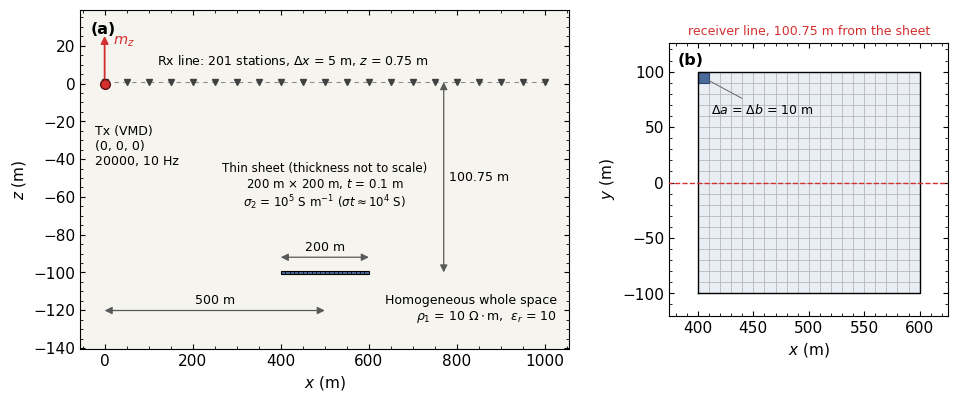

In [11]:
def profile_line(p):
    """First point, step and number of points of the plotted line: the receivers for a fixed
    source, the transmitter and receiver midpoints for a moving pair (as in OUT_DATA)."""
    if p.n_tx == 1:
        return p.xr_s.copy(), p.xr_i.copy(), p.n_rx
    return 0.5 * (p.xs_s + p.xr_s), 0.5 * (p.xs_i + p.xr_i), p.n_tx


def sheet_frame(p, is_):
    """Centre and unit vectors a (strike), b (down dip), c (normal) of a sheet (as in TS_GRID)."""
    ca, sa = ddcos(p.alpha[is_]), np.sin(p.alpha[is_])
    cb, sb = ddcos(p.beta[is_]), np.sin(p.beta[is_])
    z_rise = -0.5 * p.bb[is_] * sb
    centre = np.array([p.x_top[is_], p.y_top[is_], p.z_top[is_] - z_rise])
    a_hat = np.array([ca, sa, 0.0])
    b_hat = np.array([-sa * cb, ca * cb, sb])
    c_hat = np.array([sa * sb, -ca * sb, cb])
    return centre, a_hat, b_hat, c_hat


def sheet_crossings(p):
    """Points where the plotted line crosses the plane of each sheet, within the line and
    close to the sheet. Returns a list of (sheet index, xyz point, a, b)."""
    r0, d, n = profile_line(p)
    out = []
    for is_ in range(p.no_sheet):
        centre, a_hat, b_hat, c_hat = sheet_frame(p, is_)
        den = float(c_hat @ d)
        if abs(den) < 1e-12:
            continue
        t = float(c_hat @ (centre - r0)) / den
        if not -1e-9 <= t <= n - 1 + 1e-9:
            continue
        pt = r0 + t * d
        a, b = float((pt - centre) @ a_hat), float((pt - centre) @ b_hat)
        if abs(a) <= 0.75 * p.aa[is_] and abs(b) <= 0.75 * p.bb[is_]:
            out.append((is_, pt, a, b))
    return out


def _tex(v, digits=3):
    """A number as mathtext, with a power of ten when it is very small or very large."""
    if v == 0:
        return "0"
    v = float("%.*g" % (digits, v))
    e = int(np.floor(np.log10(abs(v))))
    if -3 <= e <= 3:
        return "%g" % v
    m = v / 10.0 ** e
    if abs(m - 1.0) < 1e-9:
        return r"10^{%d}" % e
    return r"%g\times10^{%d}" % (m, e)


def plot_model(p, sheet_note=None, tx_note=None):
    """Sketch of the model described by the parameter file. sheet_note replaces the line with the
    sheet properties and tx_note adds a line under the transmitter label."""
    ns = p.no_sheet
    names = "xyz"
    r0, d, n = profile_line(p)
    rx = p.xr_s[None, :] + np.arange(p.n_rx if p.n_tx == 1 else p.n_tx)[:, None] * p.xr_i[None, :]
    tx = p.xs_s[None, :] + np.arange(p.n_tx)[:, None] * p.xs_i[None, :]
    h = 0 if abs(d[0]) >= abs(d[1]) else 1
    blue, blue_dark, blue_light = "#4a6a9b", "#2f4a75", "#e9edf4"

    fig = plt.figure(figsize=(7.2 + 4.0 * ns, 4.4))
    gs = fig.add_gridspec(1, 1 + ns, width_ratios=[1.75] + [1.0] * ns, wspace=0.26)
    ax = fig.add_subplot(gs[0, 0])
    ax.set_facecolor("#f5f4ef")
    ax.grid(False)

    corners = []
    for is_ in range(ns):
        centre, a_hat, b_hat, c_hat = sheet_frame(p, is_)
        for sa_, sb_ in ((-1, -1), (1, -1), (1, 1), (-1, 1)):
            corners.append(centre + 0.5 * sa_ * p.aa[is_] * a_hat + 0.5 * sb_ * p.bb[is_] * b_hat)
    corners = np.array(corners)
    pts = np.vstack([corners, rx] + ([tx] if p.ns_type != 0 else []))
    h_lo, h_hi = pts[:, h].min(), pts[:, h].max()
    z_lo, z_hi = pts[:, 2].min(), pts[:, 2].max()
    h_span = max(h_hi - h_lo, 1.0)
    z_span = z_hi - z_lo if z_hi > z_lo else 0.3 * h_span
    frames = [sheet_frame(p, is_) for is_ in range(ns)]
    edge_on_all = [abs(f[3][1 - h]) < 1e-6 for f in frames]
    beside = [ns == 1 and e for e in edge_on_all]
    n_note = sum(not b for b in beside)
    ax.set_xlim(h_lo - 0.055 * h_span, h_hi + 0.055 * h_span)
    ax.set_ylim(z_lo - (0.40 + 0.20 * n_note) * z_span, z_hi + (0.38 + 0.42 * n_note) * z_span)

    # receivers (or the receivers of a moving pair)
    ax.plot(rx[:, h], rx[:, 2], ls=(0, (4, 4)), lw=0.8, color="0.55", zorder=1)
    step = max(1, len(rx) // 20)
    ax.plot(rx[::step, h], rx[::step, 2], "v", ms=4.5, color="0.25", zorder=3)
    dh = p.xr_i[h]
    if p.xr_i[2] == 0.0 and p.xr_i[1 - h] == 0.0:
        rx_txt = r"Rx line: %d stations, $\Delta %s$ = %g m, $z$ = %g m" % (len(rx), names[h], dh, p.xr_s[2])
    else:
        rx_txt = "Rx line: %d stations, step (%g, %g, %g) m" % ((len(rx),) + tuple(p.xr_i))
    vertical_dipole = p.ns_type == 0 or p.ns_dir == 3
    ax.text(rx[:, h].min() + (0.12 if vertical_dipole else 0.32) * h_span, rx[:, 2].max() + 0.075 * z_span,
            rx_txt, fontsize=9, va="bottom")

    # transmitter
    comp = names[p.ns_dir - 1] if 1 <= p.ns_dir <= 3 else "?"
    if p.ns_type == 0:
        ax.text(0.03, 0.80, "Source: plane wave (%s), incidence %g deg" % ("TM" if p.ns_dir == 1 else "TE", p.angle_deg),
                transform=ax.transAxes, fontsize=9)
    else:
        kind = ("VMD" if comp == "z" else "HMD") if p.ns_type == 2 else ("VED" if comp == "z" else "HED")
        sym = "m" if p.ns_type == 2 else "J"
        ax.plot(tx[:, h], tx[:, 2], "o", ms=7, color="#d32f2f", mec="#5d1010", mew=1.0, zorder=5)
        arrow = dict(arrowstyle="-|>", color="#d32f2f", lw=1.3, shrinkA=0, shrinkB=0)
        t0 = np.array([tx[0, h], tx[0, 2]])
        if comp == "z":
            tip = t0 + [0.0, 0.25 * z_span]
            lab, off, ha = tip, (6, -4), "left"
        elif comp == names[h]:
            tip = t0 + [0.09 * h_span, 0.0]
            lab, off, ha = tip, (4, 6), "left"
        else:
            tip = None
            lab, off, ha = t0, (8, 8), "left"
        if tip is not None:
            ax.annotate("", xy=tip, xytext=t0, arrowprops=arrow, zorder=4)
        ax.annotate(r"$%s_%s$" % (sym, comp) + ("" if tip is not None else " (out of plane)"),
                    xy=lab, xytext=off, textcoords="offset points", color="#d32f2f", fontsize=10.5, ha=ha, va="center")
        tx_txt = "Tx (%s)\n(%g, %g, %g)" % ((kind,) + tuple(p.xs_s)) if p.n_tx == 1 else \
                 "Tx (%s), %d positions\nfrom (%g, %g, %g)" % ((kind, p.n_tx) + tuple(p.xs_s))
        if tx_note is not None:
            tx_txt += "\n" + tx_note
        ax.annotate(tx_txt, xy=t0, xytext=(-7, -30), textcoords="offset points", fontsize=9, va="top", ha="left")

    # sheets, projected onto the section
    for is_ in range(ns):
        centre, a_hat, b_hat, c_hat = sheet_frame(p, is_)
        quad = corners[4 * is_:4 * is_ + 4]
        qh, qz = quad[:, h], quad[:, 2]
        b_edges = -0.5 * p.bb[is_] + np.arange(p.nb[is_] + 1) * p.bb[is_] / p.nb[is_]
        a_edges = -0.5 * p.aa[is_] + np.arange(p.na[is_] + 1) * p.aa[is_] / p.na[is_]
        edge_on = edge_on_all[is_]
        if edge_on:
            w = 0.012 * h_span
            line = np.array([centre + b * b_hat for b in b_edges])
            lh, lz = line[:, h], line[:, 2]
            nrm = np.array([-(lz[-1] - lz[0]), lh[-1] - lh[0]], dtype=float)
            nrm = nrm / max(np.hypot(*nrm), 1e-30) * np.array([1.0, z_span / h_span]) * 0.5 * w
            ax.fill([lh[0] - nrm[0], lh[-1] - nrm[0], lh[-1] + nrm[0], lh[0] + nrm[0]],
                    [lz[0] - nrm[1], lz[-1] - nrm[1], lz[-1] + nrm[1], lz[0] + nrm[1]],
                    fc=blue, ec="black", lw=0.8, zorder=2)
            for k in range(1, p.nb[is_]):
                ax.plot([lh[k] - nrm[0], lh[k] + nrm[0]], [lz[k] - nrm[1], lz[k] + nrm[1]], color="black", lw=0.5, zorder=3)
        else:
            ax.fill(qh, qz, fc=blue, ec="black", lw=0.8, alpha=0.55, zorder=2)
            for a in a_edges[1:-1]:
                e = np.array([centre + a * a_hat + b * b_hat for b in (b_edges[0], b_edges[-1])])
                ax.plot(e[:, h], e[:, 2], color="black", lw=0.3, zorder=3)
            for b in b_edges[1:-1]:
                e = np.array([centre + a * a_hat + b * b_hat for a in (a_edges[0], a_edges[-1])])
                ax.plot(e[:, h], e[:, 2], color="black", lw=0.3, zorder=3)

        tau = abs(p.tau[is_])
        txt = ("Thin sheet%s (thickness not to scale)\n" % ("" if ns == 1 else " %d" % (is_ + 1))
               + r"%g m $\times$ %g m, $t$ = %g m" % (p.aa[is_], p.bb[is_], p.thick[is_]) + "\n"
               + (sheet_note if sheet_note is not None else
                  r"$\rho_{%d}$ = $%s$ $\Omega\cdot$m ($\sigma t \approx %s$ S)" % (is_ + 2, _tex(p.res[is_][0]), _tex(tau))))
        ch, cz = centre[h], centre[2]
        right = ch <= 0.5 * (h_lo + h_hi) + 0.1 * h_span
        leader = dict(arrowstyle="-", color="0.4", lw=0.7)
        dim = dict(arrowstyle="<|-|>", color="0.35", lw=0.9, shrinkA=0, shrinkB=0)
        flat = beside[is_] and (qz.max() - qz.min()) < 1e-9 * max(z_span, 1.0)
        if flat:
            z_rx = float(rx[:, 2].mean())
            up = 1.0 if z_rx >= cz else -1.0
            gap = abs(z_rx - cz)
            ax.text(ch, cz + up * 0.45 * gap, txt, fontsize=8.5, ha="center", va="center")
            zd = cz + up * 0.08 * z_span
            ax.annotate("", xy=(qh.min(), zd), xytext=(qh.max(), zd), arrowprops=dim)
            ax.text(ch, zd + up * 0.02 * z_span, "%.4g m" % (qh.max() - qh.min()), fontsize=9, ha="center",
                    va="bottom" if up > 0 else "top")
            hd = qh.max() + 0.17 * h_span
            ax.annotate("", xy=(hd, cz), xytext=(hd, z_rx), arrowprops=dim)
            ax.text(hd + 0.012 * h_span, 0.5 * (cz + z_rx), "%.5g m" % gap, fontsize=9, ha="left", va="center")
        elif beside[is_]:
            ax.annotate(txt, xy=(ch + (0.008 if right else -0.008) * h_span, cz + 0.2 * (qz.max() - qz.min())),
                        xytext=(ch + (0.07 if right else -0.07) * h_span, cz + (0.12 - 0.5 * is_) * (qz.max() - qz.min())),
                        fontsize=8.5, ha="left" if right else "right", va="center", arrowprops=leader)
        else:
            k_note = sum(not b for b in beside[:is_])
            ax.annotate(txt, xy=(ch, qz.max() - 0.15 * (qz.max() - qz.min())),
                        xytext=(0.985, 0.975 - 0.2 * k_note), textcoords="axes fraction",
                        fontsize=8.8, ha="right", va="top", arrowprops=leader)

        if not flat and qz.max() > qz.min():
            hd = qh.min() - 0.04 * h_span if right else qh.max() + 0.04 * h_span
            ax.annotate("", xy=(hd, qz.min()), xytext=(hd, qz.max()), arrowprops=dim)
            ax.text(hd - (0.015 if right else -0.015) * h_span, 0.5 * (qz.min() + qz.max()), "%.4g m" % (qz.max() - qz.min()),
                    fontsize=9, ha="right" if right else "left", va="center")
        if ns == 1 and p.ns_type != 0 and p.n_tx == 1 and abs(ch - tx[0, h]) > 0.02 * h_span:
            zd = z_lo - 0.2 * z_span
            ax.annotate("", xy=(tx[0, h], zd), xytext=(ch, zd), arrowprops=dim)
            ax.text(0.5 * (tx[0, h] + ch), zd + 0.02 * z_span, "%.4g m" % abs(ch - tx[0, h]), fontsize=9, ha="center", va="bottom")

    host = r"$\rho_1$ = $%s$ $\Omega\cdot$m" % _tex(p.resn[0]) if p.resn[0] > 0 else "non-conducting"
    ax.text(0.975, 0.07, "Homogeneous whole space\n" + host + r",  $\varepsilon_r$ = %g" % p.epsn[0],
            transform=ax.transAxes, fontsize=9, ha="right", va="bottom")
    ax.text(0.02, 0.965, "(a)", transform=ax.transAxes, fontsize=11.5, fontweight="bold", va="top")
    ax.set_xlabel("$%s$ (m)" % names[h])
    ax.set_ylabel("$z$ (m)")

    # each sheet face on, with its cells
    cross = {c[0]: c for c in sheet_crossings(p)}
    for is_ in range(ns):
        axb = fig.add_subplot(gs[0, 1 + is_])
        axb.grid(False)
        centre, a_hat, b_hat, c_hat = sheet_frame(p, is_)
        def axis_of(vec):
            for i, nm in enumerate("xyz"):
                if abs(abs(vec[i]) - 1.0) < 1e-6:
                    return centre[i], float(np.sign(vec[i])), "$%s$ (m)" % nm
            return None

        u0, su, ulab = axis_of(a_hat) or (0.0, 1.0, "distance along strike, $a$ (m)")
        v0, sv, vlab = axis_of(b_hat) or (0.0, 1.0, "distance down dip, $b$ (m)")
        swap = ulab == "$y$ (m)" and vlab == "$x$ (m)"

        def uv(a, b):
            """In-plane coordinates (a, b) to the coordinates of the panel."""
            u, v = u0 + su * a, v0 + sv * b
            return (v, u) if swap else (u, v)

        a_edges = -0.5 * p.aa[is_] + np.arange(p.na[is_] + 1) * p.aa[is_] / p.na[is_]
        b_edges = -0.5 * p.bb[is_] + np.arange(p.nb[is_] + 1) * p.bb[is_] / p.nb[is_]
        ue, ve = u0 + su * a_edges, v0 + sv * b_edges
        da, db = p.aa[is_] / p.na[is_], p.bb[is_] / p.nb[is_]
        d_u, d_v = da, db
        if swap:
            ue, ve, ulab, vlab, d_u, d_v = ve, ue, vlab, ulab, db, da
        u_lo, u_hi, v_lo, v_hi = ue.min(), ue.max(), ve.min(), ve.max()
        axb.fill([u_lo, u_hi, u_hi, u_lo], [v_lo, v_lo, v_hi, v_hi], fc=blue_light, ec="none", zorder=1)
        axb.vlines(ue[1:-1], v_lo, v_hi, color="0.72", lw=0.6, zorder=2)
        axb.hlines(ve[1:-1], u_lo, u_hi, color="0.72", lw=0.6, zorder=2)
        axb.plot([u_lo, u_hi, u_hi, u_lo, u_lo], [v_lo, v_lo, v_hi, v_hi, v_lo], color="black", lw=1.0, zorder=4)
        axb.fill([u_lo, u_lo + d_u, u_lo + d_u, u_lo], [v_hi - d_v, v_hi - d_v, v_hi, v_hi], fc=blue, ec=blue_dark, lw=0.8, zorder=3)
        size = r"$\Delta a$ = $\Delta b$ = %.4g m" % da if abs(da - db) < 1e-9 * da else r"$\Delta a$ = %.4g m, $\Delta b$ = %.4g m" % (da, db)
        axb.annotate(size, xy=(u_lo + 0.8 * d_u, v_hi - 0.7 * d_v), xytext=(u_lo + 0.06 * (u_hi - u_lo), v_hi - 0.17 * (v_hi - v_lo)),
                     fontsize=9, va="center", arrowprops=dict(arrowstyle="-", color="0.4", lw=0.7), zorder=5)
        if is_ in cross:
            _, pt, a_c, b_c = cross[is_]
            uc, vc = uv(a_c, b_c)
            axb.plot([uc, uc], [v_lo, max(v_hi, vc)], color="#d32f2f", ls="--", lw=1.0, zorder=5)
            axb.plot([uc], [vc], "v", color="#d32f2f", mec="#5d1010", ms=5.5, zorder=6, clip_on=False)
            axb.annotate("profile crossing", xy=(uc, max(v_hi, vc)), xytext=(5, 5), textcoords="offset points",
                         color="#d32f2f", fontsize=9, va="bottom")
        else:
            e0 = r0 - centre
            e1 = r0 + (n - 1) * d - centre
            (ua, va), (ub, vb) = uv(float(e0 @ a_hat), float(e0 @ b_hat)), uv(float(e1 @ a_hat), float(e1 @ b_hat))
            axb.plot([ua, ub], [va, vb], color="#d32f2f", ls="--", lw=1.0, zorder=5)
            axb.text(0.5, 1.02, "receiver line, %.5g m from the sheet" % abs(float(c_hat @ e0)),
                     transform=axb.transAxes, color="#d32f2f", fontsize=9, ha="center", va="bottom")
        mu, mv = 0.13 * (u_hi - u_lo), 0.13 * (v_hi - v_lo)
        axb.set_xlim(u_lo - mu, u_hi + mu)
        axb.set_ylim(v_lo - mv / 1.3, v_hi + mv)
        axb.set_aspect("equal")
        axb.text(0.03, 0.965, "(%s)" % "bcdef"[is_], transform=axb.transAxes, fontsize=11.5, fontweight="bold", va="top")
        axb.set_xlabel(ulab)
        axb.set_ylabel(vlab)
    return fig


def sheet_spans(p):
    """Range of the profile coordinate covered by each sheet that the receiver line does not cross
    (for example a horizontal sheet under the line). Returns a list of (low, high)."""
    r0, d, n = profile_line(p)
    k = int(np.argmax(np.abs(d)))
    crossed = {c[0] for c in sheet_crossings(p)}
    lo_line, hi_line = sorted((r0[k], r0[k] + (n - 1) * d[k]))
    out = []
    for is_ in range(p.no_sheet):
        if is_ in crossed:
            continue
        centre, a_hat, b_hat, c_hat = sheet_frame(p, is_)
        vals = [(centre + 0.5 * sa * p.aa[is_] * a_hat + 0.5 * sb * p.bb[is_] * b_hat)[k]
                for sa in (-1, 1) for sb in (-1, 1)]
        if max(vals) >= lo_line and min(vals) <= hi_line:
            out.append((max(min(vals), lo_line), min(max(vals), hi_line)))
    return out


p_model = setup_model(read_par(par_name(FREQUENCIES[0])))
note = r"$\sigma_2$ = $%s$ S m$^{-1}$ ($\sigma t \approx %s$ S)" % (_tex(SHEET_CONDUCTIVITY), _tex(float("%.2g" % p_model.tau[0].real)))
fig = plot_model(p_model, sheet_note=note, tx_note=", ".join("%g" % f for f in FREQUENCIES) + " Hz")
plt.show()

## Run

Each frequency writes its own output file `h-field_py_horizontal_<f>Hz.dat`. Fields are magnetic field strengths in A/m for a unit dipole moment.

In [12]:
RESULTS = {}
for k, f in enumerate(FREQUENCIES):
    if k == 0:
        describe_model(setup_model(read_par(par_name(f))), par_name(f) + "  (the frequency changes from run to run)")
        print()
    RESULTS[f] = run_wsheet(par_name(f), suffix="_py_horizontal_%gHz" % f, verbose=False)
    print("%8g Hz done in %.1f s  ->  h-field_py_horizontal_%gHz.dat" % (f, RESULTS[f].elapsed, f))

r0 = RESULTS[FREQUENCIES[0]]
p = r0.p
PROF = int(np.argmax([np.ptp(v) for v in (r0.xm, r0.ym, r0.zm)]))
x = (r0.xm, r0.ym, r0.zm)[PROF]
XLABEL = "Receiver position $%s$ (m)" % "xyz"[PROF]
UNIT = r"A m$^{-1}$"
CROSSINGS = [c[1][PROF] for c in sheet_crossings(p)]
SPANS = sheet_spans(p)
CENTRE = sheet_frame(p, 0)[0]
I_SHEET = int(np.argmin(np.abs(x - CENTRE[PROF])))
TX_TO_SHEET = float(np.linalg.norm(CENTRE - p.xs_s))
COMPS = [i for i in range(3)
         if max(np.abs(r.f_sec[:, 1, i]).max() / np.abs(r.f_sec[:, 1, :]).max() for r in RESULTS.values()) > 1e-8]

print()
print("self cell: %s" % ("exact rectangle (not in the Fortran)" if EXACT_SELF_CELL else "as in the Fortran code"))
print("transmitter to sheet centre %.1f m, primary field taken at the receiver above the sheet centre, x = %g m" % (TX_TO_SHEET, x[I_SHEET]))
print("%10s %12s %14s %15s %15s %15s %12s" % ("f (Hz)", "skin depth", "Tx to sheet", "|primary Hz|", "max |sec Hx|", "max |sec Hz|", "|Hy| / max"))
print("%10s %12s %14s %15s %15s %15s %12s" % ("", "(m)", "(skin depths)", "(A/m)", "(A/m)", "(A/m)", ""))
for f in FREQUENCIES:
    r = RESULTS[f]
    delta = -1.0 / np.sqrt(complex(r.p.wave_s)).imag
    sec = np.abs(r.f_sec[:, 1, :]).max(axis=0)
    print("%10g %12.2f %14.2f %15.4e %15.4e %15.4e %12.1e"
          % (f, delta, TX_TO_SHEET / delta, abs(r.f_prim[I_SHEET, 1, 2]), sec[0], sec[2], sec[1] / sec.max()))

MODEL READ FROM wsheet20_horizontal_20000Hz.par  (the frequency changes from run to run)
  frequency            : 20000 Hz
  whole space          : resistivity 10 ohm-m, relative permittivity 10, skin depth 11.25 m
  sheet 1              : 200 m x 200 m, 20 x 20 cells, strike 90 deg, dip 0 deg, thickness 0.1 m
                         x_top, y_top, z_top = 500, 0, -100 m
                         resistivity 1e-05 ohm-m, relative permittivity 2, conductance contrast tau = 9999.99 -8.9012e-07j S
  source               : magnetic dipole, direction 3, 1 position(s) from (0, 0, 0) m
  receivers            : 201 from (0, 0, 0.75) m in steps of (5, 0, 0) m
  it_s, nprt           : 1, 1 1 0 0
  unknowns             : 800

   20000 Hz done in 10.9 s  ->  h-field_py_horizontal_20000Hz.dat
      10 Hz done in 9.4 s  ->  h-field_py_horizontal_10Hz.dat

self cell: exact rectangle (not in the Fortran)
transmitter to sheet centre 509.9 m, primary field taken at the receiver above the sheet centre, x 

## Secondary and total field at each frequency

Real and imaginary part of the secondary field, then the real part of the total field. The shaded band marks the part of the receiver line that lies above the sheet.

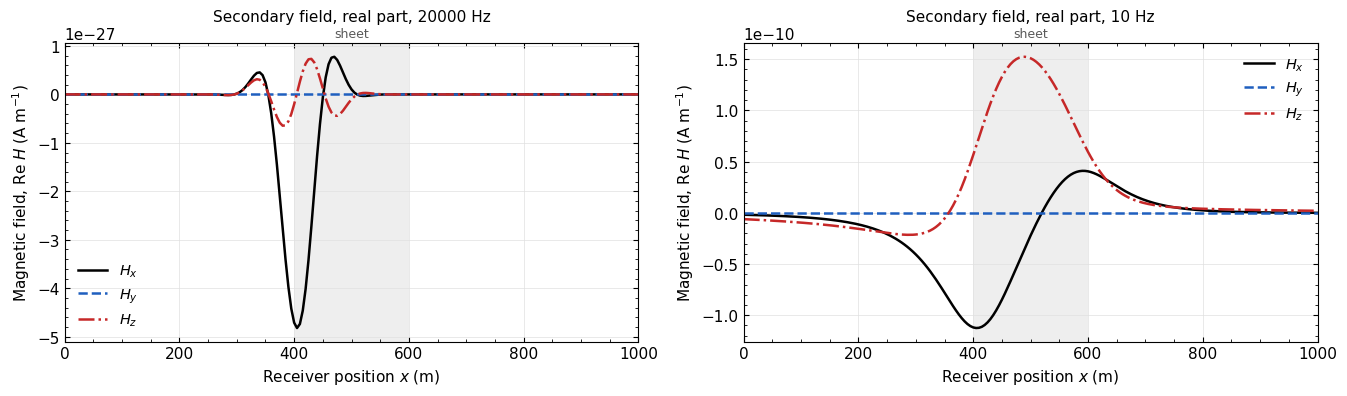

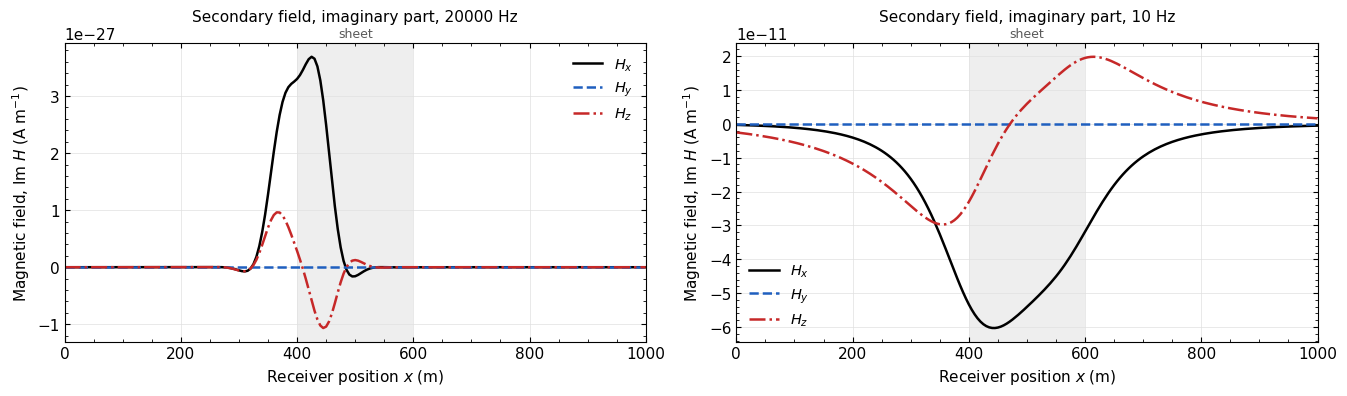

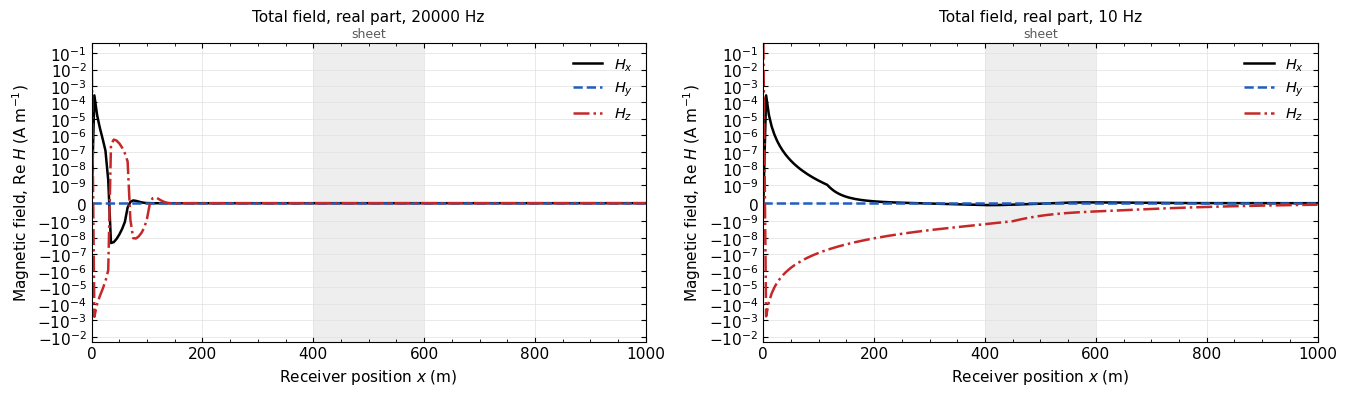

In [13]:
def mark_sheets(ax):
    """Shaded band where the receiver line passes over a sheet, dashed line where it crosses the plane of a sheet."""
    for lo, hi in SPANS:
        ax.axvspan(lo, hi, color="0.5", alpha=0.13, lw=0, zorder=0)
        ax.text(0.5 * (lo + hi), 1.012, "sheet", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=9, color="0.35")
    for xc in CROSSINGS:
        ax.axvline(xc, color="0.45", ls="--", lw=0.8, zorder=0)
        ax.text(xc, 1.012, "sheet", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=9, color="0.35")


def plot_panels(kind, part, symlog=False):
    """One panel per frequency with the x, y, z components of the secondary or total field."""
    n = len(FREQUENCIES)
    ncol = 2 if n > 1 else 1
    nrow = int(np.ceil(n / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(6.8 * ncol, 4.1 * nrow), sharex=True, squeeze=False)
    axs = axs.ravel()
    for ax in axs[n:]:
        ax.set_visible(False)
    for k, f in enumerate(FREQUENCIES):
        ax = axs[k]
        r = RESULTS[f]
        field = r.f_sec[:, 1, :] if kind == "Secondary" else r.total[:, 1, :]
        vals = field.real if part == "Re" else field.imag
        for i, c in enumerate("XYZ"):
            ax.plot(x, vals[:, i], label="$H_%s$" % c.lower(), **STYLE[c])
        ax.set_xlim(x.min(), x.max())
        mark_sheets(ax)
        if symlog:
            ax.set_yscale("symlog", linthresh=1e-9)
        else:
            ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
        ax.set_title("%s field, %s part, %g Hz" % (kind, "real" if part == "Re" else "imaginary", f), pad=16)
        ax.set_ylabel("Magnetic field, %s $H$ (%s)" % (part, UNIT))
        ax.legend(loc="best")
        if k >= n - ncol:
            ax.set_xlabel(XLABEL)
            ax.tick_params(labelbottom=True)
    plt.tight_layout()
    plt.show()


plot_panels("Secondary", "Re")
plot_panels("Secondary", "Im")
plot_panels("Total", "Re", symlog=True)

## Change of the response with frequency

Magnitude of the secondary field at the stations listed in `STATIONS`, and its real and imaginary parts at those stations.

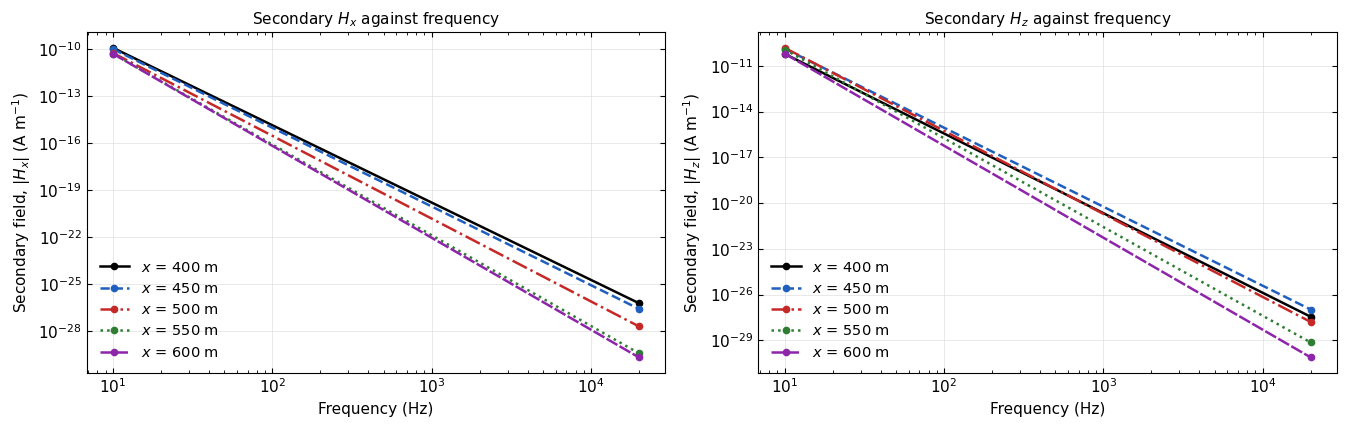

20000 Hz
   x (m)           secondary Hx (Re, Im)           secondary Hz (Re, Im)    |primary Hz|
     400         -4.7105e-27, 3.2997e-27         -2.0403e-28, 2.8587e-28      1.1693e-21
     450         -6.1454e-29, 2.4940e-27         1.1888e-28, -1.0409e-27      1.2209e-23
     500         1.0369e-28, -1.5822e-28         -1.0105e-28, 1.2561e-28      1.2912e-25
     550         -3.4130e-30, 1.1470e-30         3.7723e-30, -6.1965e-30      1.3795e-27
     600        -8.6506e-31, -1.7610e-30          5.1168e-31, 5.6499e-31      1.4865e-29

10 Hz
   x (m)           secondary Hx (Re, Im)           secondary Hz (Re, Im)    |primary Hz|
     400        -1.1191e-10, -5.3298e-11         5.6448e-11, -2.3061e-11      1.5336e-09
     450        -8.4848e-11, -6.0151e-11         1.3275e-10, -5.9329e-12      1.1182e-09
     500        -2.2186e-11, -5.4057e-11          1.5098e-10, 5.8921e-12      8.4270e-10
     550         2.6876e-11, -4.5080e-11          1.1612e-10, 1.3774e-11      6.5137e-10
     

In [14]:
LINE_COLORS = ["black", "#1f5fbf", "#c62828", "#2e7d32", "#8e24aa", "#ef6c00", "#00838f"]
LINE_STYLES = ["-", "--", "-.", ":", (0, (5, 1)), (0, (3, 1, 1, 1)), (0, (1, 1))]

i_st = [int(np.argmin(np.abs(x - s))) for s in STATIONS]
order = np.argsort(FREQUENCIES)
fr = np.array(FREQUENCIES)[order]
fig, axs = plt.subplots(1, len(COMPS), figsize=(6.8 * len(COMPS), 4.4), squeeze=False)
for ax, i in zip(axs[0], COMPS):
    for k, ist in enumerate(i_st):
        vals = np.array([abs(RESULTS[f].f_sec[ist, 1, i]) for f in FREQUENCIES])[order]
        ax.loglog(fr, vals, marker="o", ms=4.5, color=LINE_COLORS[k % 7], ls=LINE_STYLES[k % 7],
                  label="$%s$ = %g m" % ("xyz"[PROF], x[ist]))
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Secondary field, |$H_%s$| (%s)" % ("xyz"[i], UNIT))
    ax.set_title("Secondary $H_%s$ against frequency" % "xyz"[i])
    ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

for f in sorted(FREQUENCIES, reverse=True):
    r = RESULTS[f]
    print("%g Hz" % f)
    print("%8s" % "x (m)" + "".join("%32s" % ("secondary H%s (Re, Im)" % "xyz"[i]) for i in COMPS) + "%16s" % "|primary Hz|")
    for ist in i_st:
        row = "%8g" % x[ist]
        for i in COMPS:
            v = r.f_sec[ist, 1, i]
            row += "%32s" % ("%.4e, %.4e" % (v.real, v.imag))
        print(row + "%16.4e" % abs(r.f_prim[ist, 1, 2]))
    print()